# Part 4: Gradient Descent in Code

Here we turn the Part 3 manual calculations into Python.

Model: **ŷ = m1·x1 + m2·x2 + b**, written with matrices as **ŷ = X·m + b**

- Initial m = [-1, 2], initial b = [1, 1], learning rate α = 0.01
- Data: x = ((1, 3), (4, 10)), y = (5, 6)
- Cost: Mean Squared Error, J(m, b) = (1/n) Σ (ŷ − y)²

In [2]:
import numpy as np

m = np.array([-1.0, 2.0])
b = np.array([1.0, 1.0])
a = 0.01
iterations = 3   # number of updates = number of group members (same as Part 3)

x = np.array([(1, 3), (4,10)])
y =np.array([5, 6])

def predict(X, m, b):
    y_hat = X@m + b
    return y_hat

predict(x,m,b)

array([ 6., 17.])

In [3]:
def compute_error(y_hat, y):
    error = y_hat -y
    return error

errors = compute_error(predict(x,m,b), y)
print(errors)

[ 1. 11.]


In [4]:
def compute_cost(errors):
    cost = np.mean(errors ** 2)
    return cost

cost = compute_cost(errors)
print(cost)

61.0


### Gradient of the cost

Using the chain rule on J = (1/n) Σ (ŷ − y)², with ŷ = X·m + b:

- ∂J/∂m = (2/n) · Xᵀ · (ŷ − y)
- ∂J/∂b = (2/n) · Σ (ŷ − y)

The `2` comes from the derivative of the square, and `Xᵀ` (or `1` for b) comes from the derivative of ŷ.

In [5]:
def compute_gradient(X, error):
    n = len(X)
    dj_dm = 2/n * X.T @ error
    dj_db = 2/n *np.sum(error)

    return dj_dm, dj_db

dj_dm, dj_db = compute_gradient(x, errors)
print(dj_dm, dj_db)

[ 45. 113.] 12.0


In [6]:
def update(m, b, dj_dm, dj_db, a):
    m_new = m - a*dj_dm

    b_new = b - a*dj_db

    return m_new,b_new

print(update(m,b,dj_dm, dj_db, a))

(array([-1.45,  0.87]), array([0.88, 0.88]))


### Derivatives with SciPy

`compute_derivative` accepts any equation (a Python function) and a point, and returns the derivative at that point using `scipy.differentiate.derivative`.
We use it on the cost equation to get ∂J/∂m1, ∂J/∂m2 and ∂J/∂b, and check them against our formula above.

In [7]:
from scipy.differentiate import derivative

def compute_derivative(equation, point):
    return derivative(np.vectorize(equation), point).df

print("d/dt of t^2 at t = 3:", compute_derivative(lambda t: t**2, 3.0))

def cost_equation(m, b):
    return compute_cost(compute_error(predict(x, m, b), y))

def scipy_gradient(m, b):
    dj_dm1 = compute_derivative(lambda t: cost_equation(np.array([t, m[1]]), b), m[0])
    dj_dm2 = compute_derivative(lambda t: cost_equation(np.array([m[0], t]), b), m[1])
    dj_db = compute_derivative(lambda t: cost_equation(m, b + t), 0.0)
    return np.array([dj_dm1, dj_dm2]), dj_db

print("scipy:", scipy_gradient(m, b))
print("ours: ", compute_gradient(x, errors))

d/dt of t^2 at t = 3: 5.999999999999972
scipy: (array([ 45., 113.]), np.float64(12.000000000000227))
ours:  (array([ 45., 113.]), np.float64(12.0))


### Updating m and b

Each iteration: predict ŷ → compute error → compute gradient → update m and b → compute the new cost.
Every step is printed so it can be compared with our Part 3 manual calculations.

In [8]:
def gradient_descent(m, b, a, iterations, show_steps):
    history = [(m[0], m[1], b[0], cost_equation(m, b))]

    for i in range(1, iterations + 1):
        y_hat = predict(x, m, b)
        errors = compute_error(y_hat, y)
        dj_dm, dj_db = compute_gradient(x, errors)
        scipy_dm, scipy_db = scipy_gradient(m, b)
        m, b = update(m, b, dj_dm, dj_db, a)
        cost = cost_equation(m, b)
        history.append((m[0], m[1], b[0], cost))

        if show_steps:
            print(f"--- iteration {i} ---")
            print("y_hat:", y_hat)
            print("error:", errors)
            print("dJ/dm:", dj_dm, "  scipy:", scipy_dm)
            print("dJ/db:", dj_db, "  scipy:", scipy_db)
            print("new m:", m, "  new b:", b)
            print("cost: ", cost)

    return m, b, np.array(history)

m_final, b_final, history = gradient_descent(m, b, a, iterations, show_steps=True)

--- iteration 1 ---
y_hat: [ 6. 17.]
error: [ 1. 11.]
dJ/dm: [ 45. 113.]   scipy: [ 45. 113.]
dJ/db: 12.0   scipy: 12.000000000000227
new m: [-1.45  0.87]   new b: [0.88 0.88]
cost:  6.845000000000002
--- iteration 2 ---
y_hat: [2.04 3.78]
error: [-2.96 -2.22]
dJ/dm: [-11.84 -31.08]   scipy: [-11.84 -31.08]
dJ/db: -5.1800000000000015   scipy: -5.180000000000035
new m: [-1.3316  1.1808]   new b: [0.9318 0.9318]
cost:  2.72381716
--- iteration 3 ---
y_hat: [3.1426 7.4134]
error: [-1.8574  1.4134]
dJ/dm: [3.7962 8.5618]   scipy: [3.7962 8.5618]
dJ/db: -0.4439999999999995   scipy: -0.4440000000000026
new m: [-1.369562  1.095182]   new b: [0.93624 0.93624]
cost:  2.3904438107600003


### Predictions with the final m and b

In [9]:
print("final m:", m_final, "  final b:", b_final)
print("predictions:", predict(x, m_final, b_final), "  real y:", y)

m_long, b_long, long_history = gradient_descent(m, b, a, 2000, show_steps=False)
print("\nafter 2000 iterations")
print("final m:", m_long, "  final b:", b_long)
print("predictions:", predict(x, m_long, b_long), "  real y:", y)

final m: [-1.369562  1.095182]   final b: [0.93624 0.93624]
predictions: [2.852224 6.409812]   real y: [5 6]

after 2000 iterations
final m: [-2.22575528  1.09677519]   final b: [3.93530626 3.93530626]
predictions: [4.99987656 6.00003708]   real y: [5 6]


### Plots

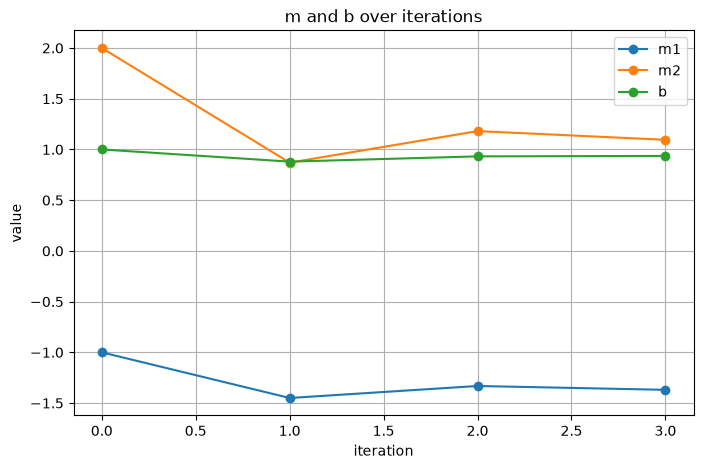

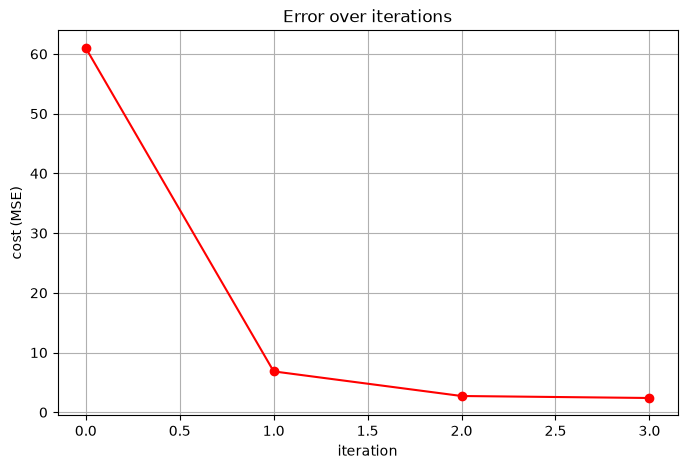

In [10]:
import matplotlib.pyplot as plt

def plot_parameters(history, title, filename):
    marker = "o" if len(history) <= 20 else None
    plt.figure(figsize=(8, 5))
    plt.plot(history[:, 0], marker=marker, label="m1")
    plt.plot(history[:, 1], marker=marker, label="m2")
    plt.plot(history[:, 2], marker=marker, label="b")
    plt.xlabel("iteration")
    plt.ylabel("value")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.savefig(filename)
    plt.show()

def plot_cost(history, title, filename):
    marker = "o" if len(history) <= 20 else None
    plt.figure(figsize=(8, 5))
    plt.plot(history[:, 3], marker=marker, color="red")
    plt.xlabel("iteration")
    plt.ylabel("cost (MSE)")
    plt.title(title)
    plt.grid(True)
    plt.savefig(filename)
    plt.show()

plot_parameters(history, "m and b over iterations", "figures/1_m_and_b.png")
plot_cost(history, "Error over iterations", "figures/2_error.png")

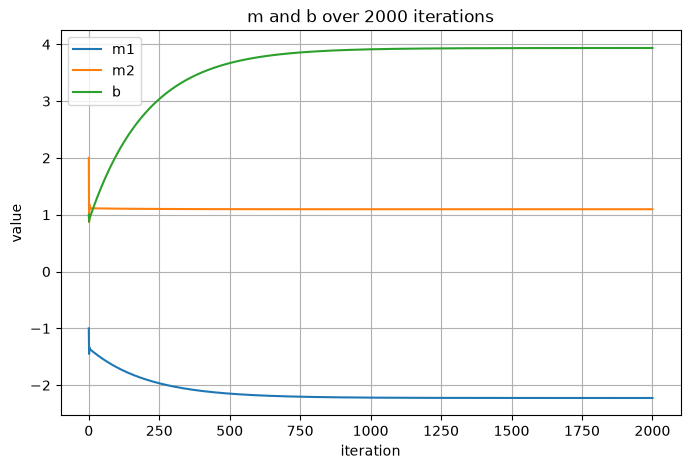

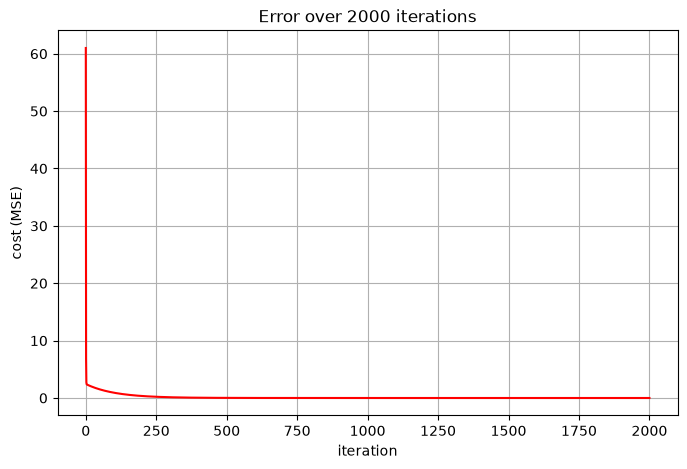

In [11]:
plot_parameters(long_history, "m and b over 2000 iterations", "figures/3_m_and_b_long.png")
plot_cost(long_history, "Error over 2000 iterations", "figures/4_error_long.png")

### What we observe

- The cost drops from **61** to **6.845** after the first update, then to **2.72** and **2.39**, so every update reduces the error.
- The first update is a big jump (m2 goes from 2 to 0.87) because the starting error for the second point (11) is large and x2 = 10 makes ∂J/∂m2 = 113 big. After that, m and b move in smaller steps.
- m2 overshoots, then settles. b dips to 0.88 on the first update, then rises slowly because the predictions are now below the real y values, which pushes the line up.
- If we keep going for 2000 iterations, the cost goes to almost 0. With 3 parameters and only 2 points, the line can pass exactly through both points, giving predictions ≈ (5, 6).
- SciPy's numerical derivatives match our chain rule formulas at every step, which confirms our Part 3 derivation.